# Loading data

In [34]:
import pickle
import numpy as np
import pandas as pd
import os

In [69]:
df_data = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Datasets/DiaTrend/Glucose_measurements_v3_DiaTrend.parquet')
df_data

,Patient_ID,Measurement_date,Measurement_time,Measurement,15min,5min
0,1,2015-12-01,0 days 21:01:07,160.00000,2015-12-01 21:00:00,2015-12-01 21:00:00
1,1,2015-12-01,0 days 21:06:07,161.00000,NaT,2015-12-01 21:05:00
2,1,2015-12-01,0 days 21:11:08,165.00000,NaT,2015-12-01 21:10:00
3,1,2015-12-01,0 days 21:16:08,162.00000,2015-12-01 21:15:00,2015-12-01 21:15:00
4,1,2015-12-01,0 days 21:21:07,163.00000,NaT,2015-12-01 21:20:00
...,...,...,...,...,...,...
9192454,54,2019-07-09,0 days 14:52:48,134.88318,NaT,2019-07-09 14:55:00
9192455,54,2019-07-09,0 days 14:57:48,132.88482,2019-07-09 15:00:00,2019-07-09 15:00:00
9192456,54,2019-07-09,0 days 15:02:48,131.88582,NaT,2019-07-09 15:05:00
9192457,54,2019-07-09,0 days 15:07:48,131.88582,NaT,2019-07-09 15:10:00


In [70]:
# Filter valid rows (15min is not NaT)
df_valid_rows = df_data[df_data['15min'].notna()]
df_valid_rows

,Patient_ID,Measurement_date,Measurement_time,Measurement,15min,5min
0,1,2015-12-01,0 days 21:01:07,160.00000,2015-12-01 21:00:00,2015-12-01 21:00:00
3,1,2015-12-01,0 days 21:16:08,162.00000,2015-12-01 21:15:00,2015-12-01 21:15:00
6,1,2015-12-01,0 days 21:31:13,167.00000,2015-12-01 21:30:00,2015-12-01 21:30:00
10,1,2015-12-01,0 days 21:46:07,150.00000,2015-12-01 21:45:00,2015-12-01 21:45:00
13,1,2015-12-01,0 days 22:01:07,164.00000,2015-12-01 22:00:00,2015-12-01 22:00:00
...,...,...,...,...,...,...
9192446,54,2019-07-09,0 days 14:12:48,144.87444,2019-07-09 14:15:00,2019-07-09 14:15:00
9192449,54,2019-07-09,0 days 14:27:48,143.87544,2019-07-09 14:30:00,2019-07-09 14:30:00
9192452,54,2019-07-09,0 days 14:42:48,137.88054,2019-07-09 14:45:00,2019-07-09 14:45:00
9192455,54,2019-07-09,0 days 14:57:48,132.88482,2019-07-09 15:00:00,2019-07-09 15:00:00


In [71]:
df_valid_rows['Patient_ID'] = df_valid_rows['Patient_ID'].astype(int)  # Ensure Patient_ID is string type
df_valid_rows = df_valid_rows.sort_values(by=['Patient_ID', '15min'])
df_valid_rows.reset_index(drop=True, inplace=True)  # Reset index after filtering
df_valid_rows

C:\Users\Ciro\AppData\Local\Temp\ipykernel_17444\3655810709.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_valid_rows['Patient_ID'] = df_valid_rows['Patient_ID'].astype(int)  # Ensure Patient_ID is string type


,Patient_ID,Measurement_date,Measurement_time,Measurement,15min,5min
0,1,2015-12-01,0 days 21:01:07,160.00000,2015-12-01 21:00:00,2015-12-01 21:00:00
1,1,2015-12-01,0 days 21:16:08,162.00000,2015-12-01 21:15:00,2015-12-01 21:15:00
2,1,2015-12-01,0 days 21:31:13,167.00000,2015-12-01 21:30:00,2015-12-01 21:30:00
3,1,2015-12-01,0 days 21:46:07,150.00000,2015-12-01 21:45:00,2015-12-01 21:45:00
4,1,2015-12-01,0 days 22:01:07,164.00000,2015-12-01 22:00:00,2015-12-01 22:00:00
...,...,...,...,...,...,...
2927110,54,2019-07-09,0 days 14:12:48,144.87444,2019-07-09 14:15:00,2019-07-09 14:15:00
2927111,54,2019-07-09,0 days 14:27:48,143.87544,2019-07-09 14:30:00,2019-07-09 14:30:00
2927112,54,2019-07-09,0 days 14:42:48,137.88054,2019-07-09 14:45:00,2019-07-09 14:45:00
2927113,54,2019-07-09,0 days 14:57:48,132.88482,2019-07-09 15:00:00,2019-07-09 15:00:00


In [62]:
df_1 = df_valid_rows[df_valid_rows['Patient_ID'] == 1]
df_1_mea = df_1.groupby(['Measurement_date'], as_index=False).count()
df_1_mea

,Measurement_date,Patient_ID,Measurement_time,Measurement,15min,5min
0,2015-12-01,12,12,12,12,12
1,2015-12-04,18,18,18,18,18
2,2015-12-05,70,70,70,70,70
3,2015-12-06,85,85,85,85,85
4,2015-12-07,77,77,77,77,77
...,...,...,...,...,...,...
1902,2021-11-14,96,96,96,96,96
1903,2021-11-15,96,96,96,96,96
1904,2021-11-16,96,96,96,96,96
1905,2021-11-17,96,96,96,96,96


<Axes: title={'center': 'Number of Measurements per Day for Patient 1'}>

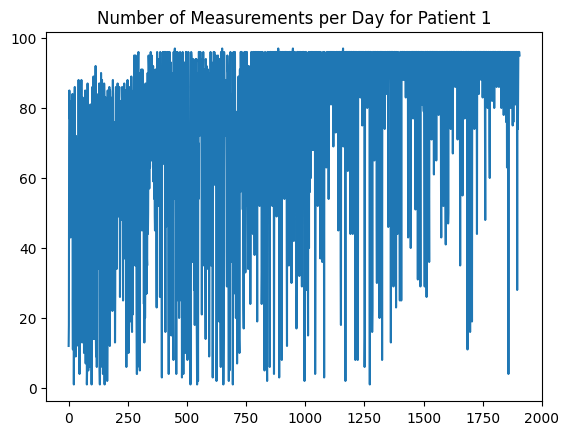

In [63]:
df_1_mea['Measurement'].plot(title='Number of Measurements per Day for Patient 1')

In [64]:
df_1_mea['Measurement'].describe()

count    1907.000000
mean       76.521762
std        25.910855
min         1.000000
25%        64.000000
50%        90.000000
75%        96.000000
max        97.000000
Name: Measurement, dtype: float64

<Axes: title={'center': 'Boxplot of Measurements per Day for Patient 1'}>

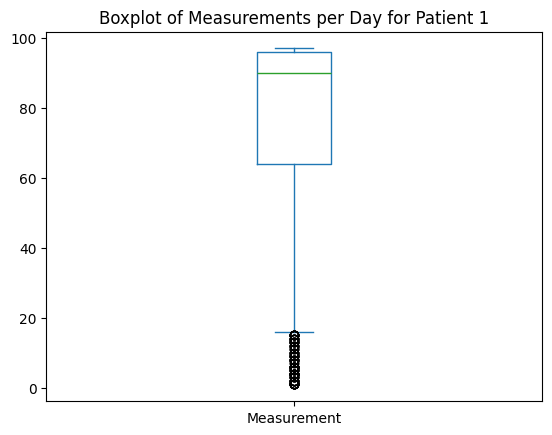

In [68]:
df_1_mea['Measurement'].plot.box(title='Boxplot of Measurements per Day for Patient 1')

In [50]:
df_valid_rows[df_valid_rows['Patient_ID'] == 2]

,Patient_ID,Measurement_date,Measurement_time,Measurement,15min,5min
209196,2,2015-12-04,0 days 06:46:22,107.0,2015-12-04 06:45:00,2015-12-04 06:45:00
209197,2,NaT,NaT,NaN,2015-12-04 07:00:00,2015-12-04 07:00:00
209198,2,2015-12-04,0 days 07:16:23,169.0,2015-12-04 07:15:00,2015-12-04 07:15:00
209199,2,2015-12-04,0 days 07:31:22,197.0,2015-12-04 07:30:00,2015-12-04 07:30:00
209200,2,NaT,NaT,NaN,2015-12-04 07:45:00,2015-12-04 07:45:00
...,...,...,...,...,...,...
402317,2,2021-06-06,0 days 22:59:07,350.0,2021-06-06 23:00:00,2021-06-06 23:00:00
402318,2,2021-06-06,0 days 23:14:07,333.0,2021-06-06 23:15:00,2021-06-06 23:15:00
402319,2,2021-06-06,0 days 23:29:07,365.0,2021-06-06 23:30:00,2021-06-06 23:30:00
402320,2,2021-06-06,0 days 23:44:06,401.0,2021-06-06 23:45:00,2021-06-06 23:45:00


In [51]:
df_valid_rows.iloc[209196 - 5 : 209196 + 5]  # Check the rows around the bad index

,Patient_ID,Measurement_date,Measurement_time,Measurement,15min,5min
209191,1,2021-11-18,0 days 22:46:51,156.0,2021-11-18 22:45:00,2021-11-18 22:45:00
209192,1,2021-11-18,0 days 23:01:51,125.0,2021-11-18 23:00:00,2021-11-18 23:00:00
209193,1,2021-11-18,0 days 23:16:51,152.0,2021-11-18 23:15:00,2021-11-18 23:15:00
209194,1,2021-11-18,0 days 23:31:52,116.0,2021-11-18 23:30:00,2021-11-18 23:30:00
209195,1,2021-11-18,0 days 23:46:51,124.0,2021-11-18 23:45:00,2021-11-18 23:45:00
209196,2,2015-12-04,0 days 06:46:22,107.0,2015-12-04 06:45:00,2015-12-04 06:45:00
209197,2,NaT,NaT,NaN,2015-12-04 07:00:00,2015-12-04 07:00:00
209198,2,2015-12-04,0 days 07:16:23,169.0,2015-12-04 07:15:00,2015-12-04 07:15:00
209199,2,2015-12-04,0 days 07:31:22,197.0,2015-12-04 07:30:00,2015-12-04 07:30:00
209200,2,NaT,NaT,NaN,2015-12-04 07:45:00,2015-12-04 07:45:00


In [41]:
df_valid_rows.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2927115 entries, 0 to 1497264
Data columns (total 6 columns):
 #   Column            Dtype          
---  ------            -----          
 0   Patient_ID        object         
 1   Measurement_date  datetime64[ns] 
 2   Measurement_time  timedelta64[us]
 3   Measurement       float64        
 4   15min             datetime64[ns] 
 5   5min              datetime64[ns] 
dtypes: datetime64[ns](3), float64(1), object(1), timedelta64[us](1)
memory usage: 156.3+ MB


In [ ]:
mismatch = df_valid_rows.index.to_numpy() != original_index.to_numpy()
wrong_positions = original_index[mismatch]
wrong_positions

In [42]:
df_valid_rows.iloc[209196 - 5 : 209196 + 5]  # Check the rows around the bad index

,Patient_ID,Measurement_date,Measurement_time,Measurement,15min,5min
209191,1,2021-11-18,0 days 22:46:51,156.0,2021-11-18 22:45:00,2021-11-18 22:45:00
209192,1,2021-11-18,0 days 23:01:51,125.0,2021-11-18 23:00:00,2021-11-18 23:00:00
209193,1,2021-11-18,0 days 23:16:51,152.0,2021-11-18 23:15:00,2021-11-18 23:15:00
209194,1,2021-11-18,0 days 23:31:52,116.0,2021-11-18 23:30:00,2021-11-18 23:30:00
209195,1,2021-11-18,0 days 23:46:51,124.0,2021-11-18 23:45:00,2021-11-18 23:45:00
1497265,10,2018-09-29,0 days 15:43:01,283.0,2018-09-29 15:45:00,2018-09-29 15:45:00
1497266,10,2018-09-29,0 days 15:58:01,287.0,2018-09-29 16:00:00,2018-09-29 16:00:00
1497267,10,2018-09-29,0 days 16:13:01,265.0,2018-09-29 16:15:00,2018-09-29 16:15:00
1497268,10,2018-09-29,0 days 16:28:01,238.0,2018-09-29 16:30:00,2018-09-29 16:30:00
1497269,10,2018-09-29,0 days 16:43:01,225.0,2018-09-29 16:45:00,2018-09-29 16:45:00


In [ ]:
df_valid_rows['Patient_ID'].value_counts()

In [ ]:
df_valid_rows.index.is_monotonic_increasing

In [ ]:
df_valid_rows['15min'].is_monotonic_increasing

In [ ]:
bad_indices = []
for pid, group in df_valid_rows.groupby('Patient_ID'):
    out_of_order = group['15min'] < group['15min'].shift()
    bad_indices.extend(group.index[out_of_order])

In [ ]:
bad_indices

In [ ]:
df_valid_rows.iloc[402322 - 5 : 402322 + 5]  # Check the rows around the bad index

In [72]:

# Group by 'Patient_ID' and convert 'Measurement' to numpy array
patient_dict = {
    pid: group['Measurement'].to_numpy()  # Convert to int32
    for pid, group in df_valid_rows.groupby('Patient_ID')
}
print(f"Number of patients with valid data: {len(patient_dict)}")

Number of patients with valid data: 54


In [73]:
patient_dict

{1: array([160., 162., 167., ..., 152., 116., 124.]),
 2: array([107.,  nan, 169., ..., 365., 401., 387.]),
 3: array([224., 212., 238., ..., 361., 355., 346.]),
 4: array([ nan, 121., 130., ..., 146., 129., 116.]),
 5: array([199., 198., 201., ..., 276., 343., 360.]),
 6: array([134., 123., 116., ..., 175., 201., 217.]),
 7: array([232., 241., 239., ..., 303., 330., 322.]),
 8: array([ 55.,  66., 114., ..., 252., 243., 231.]),
 9: array([110., 120.,  95., ..., 126., 152., 164.]),
 10: array([283., 287., 265., ..., 141., 158., 163.]),
 11: array([152., 195., 215., ..., 308., 278., 242.]),
 12: array([ 92., 107., 111., ..., 221., 218., 212.]),
 13: array([135., 130., 120., ..., 185., 165., 152.]),
 14: array([309., 318., 311., ..., 266., 267., 264.]),
 15: array([157., 188., 209., ..., 240., 229., 208.]),
 16: array([396., 401., 399., ..., 117., 104., 102.]),
 17: array([185., 167., 146., ..., 262., 231., 185.]),
 18: array([162., 146., 140., ..., 225., 232., 230.]),
 19: array([179., 1

In [74]:
df_data[df_data['Patient_ID'] == '2']['Measurement_time'].iloc[0]

Timedelta('0 days 06:41:23')

In [ ]:


# Define the file path (Replace with your filepath)
file_path_train = "C:/Users/Ciro/Mi Unidad (PDI)/_UGR_PDI_2024-05-30/RELIEF-T1D/Python_projects/HeterogeneityInfluence/Dataset/Preprocessed data/measurements_by_patient_train.pkl"
file_path_test = "C:/Users/Ciro/Mi Unidad (PDI)/_UGR_PDI_2024-05-30/RELIEF-T1D/Python_projects/HeterogeneityInfluence/Dataset/Preprocessed data/measurements_by_patient_test.pkl"
file_path_val = "C:/Users/Ciro/Mi Unidad (PDI)/_UGR_PDI_2024-05-30/RELIEF-T1D/Python_projects/HeterogeneityInfluence/Dataset/Preprocessed data/measurements_by_patient_val.pkl"

# Open files
with open(file_path_train, 'rb') as file:
    train_dict = pickle.load(file)

with open(file_path_test, 'rb') as file:
    test_dict = pickle.load(file)

with open(file_path_val, 'rb') as file:
    val_dict = pickle.load(file)
    
# data_dict = {}
# data_dict.update(train_dict)
# data_dict.update(val_dict)
# data_dict.update(test_dict)
# len(data_dict)

In [ ]:
# Windows creation parameters
history_length = 8  # 120 min
horizons = [2, 4, 6, 8, 12, 16]  # 2 for 30 min, 4 for 60 min, etc.

path = 'c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/windows/no_split_2025_DiaTrend/'
if not os.path.exists(path):
    # Si no existe, crearlo
    os.makedirs(path)


# Auxiliary function
def get_windows_one_step_walk_forward(bgl_measurement_dict, 
                                      history_length, horizon, 
                                      deduplicate_intra_patient=True) -> pd.DataFrame:
    """
      :param bgl_measurement_dict: Dictionary with patient_id as key and numpy array of temporal series of BGL measurements
      :param history_length: Number of samples used to predict (8 for 120 minutes)
      :param horizon: Prediction horizon in number of windows (2 for 30 minutes, 4 for 60 minutes, and so on)
      :return: Get windows without missing values from one step sliding windows
    """
    df_all_patient_set = pd.DataFrame()

    for patient_id, patient_series in bgl_measurement_dict.items():
        # print(f"Clave: {patient_id} — Valor: {patient_series}")

        # Creating the one step sliding window
        x = np.lib.stride_tricks.sliding_window_view(patient_series[:-horizon], history_length)
        y = np.lib.stride_tricks.sliding_window_view(patient_series[history_length:], horizon)

        # Removing rows with missing values (NaN)
        nan_rows_x = np.isnan(x).any(axis=1)  # In input values
        nan_rows_y = np.isnan(y).any(axis=1)  # In output values
        x = x[~(nan_rows_x | nan_rows_y)]  # Remove rows with NaN in either x or y from x
        y = y[~(nan_rows_x | nan_rows_y)]  # Remove rows with NaN in either x or y from y

        # Create DataFrame for the current patient
        df_x = pd.DataFrame(x)  # Input windows
        df_y = pd.DataFrame(y[:, -1])  # Output windows (last column of y)
        df_set = pd.concat([df_x, df_y], axis=1)  # Combine inputs and outputs
        df_set = df_set.astype(int)  # Convert to integer type

        # Renaming columns and adding patient_id.
        # Input: x0 a x7, Output: y
        new_cols = [f"x{i}" for i in range(8)] + ["y"]
        df_set.columns = new_cols
        df_set['patient_id'] = patient_id
        
        # Concat the current patient's DataFrame to the main DataFrame
        df_all_patient_set = pd.concat([df_all_patient_set, df_set], ignore_index=True)
    
    if deduplicate_intra_patient:
        # Drop duplicated instances in a patient. All columns are considered for duplication, therefore, if a patient has the same input and output values, it will be considered a duplicate, but if there are two equal instances but from different patients, they will not be considered duplicates. 
        df_all_patient_set = df_all_patient_set.drop_duplicates()
        df_all_patient_set.reset_index(drop=True, inplace=True)
    
    return df_all_patient_set


for current_horizon in horizons:
    print(f"Processing horizon: {current_horizon}")
    df_windows = get_windows_one_step_walk_forward(bgl_measurement_dict=patient_dict, 
                                                   history_length=history_length, 
                                                   horizon=current_horizon, 
                                                   deduplicate_intra_patient=True)
    
        # NOTE: Replace with your filepath
    df_windows.to_parquet(f'{path}/train_windows_horizon_{current_horizon}.parquet')
    print(f"Saved windows for horizon {current_horizon} to parquet files.")
    print("--------------------------------------------------")
    print()


In [ ]:
df_windows